In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px


import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.utils import to_categorical

from sklearn.metrics import confusion_matrix , classification_report 
from sklearn.preprocessing import LabelBinarizer
from sklearn.metrics import roc_curve, auc, roc_auc_score

from IPython.display import clear_output
import warnings
warnings.filterwarnings('ignore')

from keras.models import model_from_json
from keras.layers import Flatten
import cv2, os

from keras.layers import MaxPooling2D

**TRAINING**

In [4]:
train_dir = r'../input/human-action-recognition-dataset/Structured/train'
test_dir = r'../input/human-action-recognition-dataset/Structured/test'

BATCH_SIZE = 64
NUM_CLASSES = 15
IMG_WIDTH, IMG_HEIGHT = 224, 224

In [5]:
#generating data
preprocess_fn = tf.keras.applications.resnet.preprocess_input

train_datagen = ImageDataGenerator(rescale= 1./255,
                                  horizontal_flip= True,
                                  width_shift_range= 0.05,
                                  height_shift_range= 0.1,
                                  rotation_range= 10,
                                  preprocessing_function= preprocess_fn
                                  )

test_datagen = ImageDataGenerator(rescale= 1./255,
                                 preprocessing_function= preprocess_fn)

train_generator = train_datagen.flow_from_directory(directory= train_dir,
                                                    target_size= (IMG_HEIGHT, IMG_WIDTH),
                                                    batch_size = BATCH_SIZE,
                                                    shuffle = True,
                                                    color_mode = 'rgb',
                                                    subset = 'training',
                                                    class_mode = 'categorical',
                                                    seed = 2
                                                   )

test_generator = test_datagen.flow_from_directory(directory= test_dir,
                                                 target_size = (IMG_HEIGHT, IMG_WIDTH),
                                                 batch_size = BATCH_SIZE,
                                                 shuffle= False,
                                                 color_mode= 'rgb',
                                                 class_mode = 'categorical',
                                                 seed = 2)

Found 10710 images belonging to 15 classes.
Found 1890 images belonging to 15 classes.


In [6]:
base_model = tf.keras.applications.resnet.ResNet152(input_shape=(IMG_WIDTH,IMG_HEIGHT,3), weights='imagenet',
                                                    include_top=False)

base_model.summary()

234708992/234698864 [==============================] - 1s 0us/step
Model: "resnet152"
__________________________________________________________________________________________________
Layer (type)                    Output Shape         Param #     Connected to                     
input_1 (InputLayer)            [(None, 224, 224, 3) 0                                            
__________________________________________________________________________________________________
conv1_pad (ZeroPadding2D)       (None, 230, 230, 3)  0           input_1[0][0]                    
__________________________________________________________________________________________________
conv1_conv (Conv2D)             (None, 112, 112, 64) 9472        conv1_pad[0][0]                  
__________________________________________________________________________________________________
conv1_bn (BatchNormalization)   (None, 112, 112, 64) 256         conv1_conv[0][0]                 
_______________________

In [10]:
#creating model pipeline
def final_model(inputs):
    x = base_model(inputs)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dense(NUM_CLASSES, activation='softmax', name='classification')(x)
    
    return x

def compile_model():
    inputs = tf.keras.layers.Input(shape=(IMG_WIDTH, IMG_HEIGHT, 3))
    outputs  = final_model(inputs)
    model = tf.keras.Model(inputs= inputs, outputs= outputs)
    model.compile(optimizer= tf.keras.optimizers.SGD(0.001), loss='categorical_crossentropy',
                 metrics=['acc'])
    
    return model

In [11]:
#compiling model
model = compile_model()

model.summary()

Model: "model"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_2 (InputLayer)         [(None, 224, 224, 3)]     0         
_________________________________________________________________
resnet152 (Functional)       (None, 7, 7, 2048)        58370944  
_________________________________________________________________
global_average_pooling2d (Gl (None, 2048)              0         
_________________________________________________________________
classification (Dense)       (None, 15)                30735     
Total params: 58,401,679
Trainable params: 58,250,255
Non-trainable params: 151,424
_________________________________________________________________


In [24]:
#loading saved model along with weights
model_path = r'./ResNet152.json'
weights_path = r'./ResNet152_HAR-033-0.923063-0.804233.h5'
model = Load_Model(model_path, weights_path)

model.summary()

FileNotFoundError: [Errno 2] Unable to open file (unable to open file: name = './ResNet152_HAR-033-0.923063-0.804233.h5', errno = 2, error message = 'No such file or directory', flags = 0, o_flags = 0)

In [12]:
#start training
checkpoint = tf.keras.callbacks.ModelCheckpoint('ResNet152_HAR-{epoch:03d}-{acc:03f}-{val_acc:03f}.h5',
                                          save_best_only=True, monitor='val_acc', verbose=1)

#earlystopping = tf.keras.callbacks.EarlyStopping(monitor= 'val_loss')

train_stats = model.fit(train_generator,
                        batch_size= BATCH_SIZE,
                        validation_data= test_generator,
                        validation_batch_size= BATCH_SIZE,
                        epochs= 50,
                        callbacks=[checkpoint]
                        )

Epoch 1/50
168/168 [==============================] - 190s 1s/step - loss: 2.5098 - acc: 0.2135 - val_loss: 3.1225 - val_acc: 0.0730

Epoch 00001: val_acc improved from -inf to 0.07302, saving model to ResNet152_HAR-001-0.213539-0.073016.h5
Epoch 2/50
168/168 [==============================] - 143s 846ms/step - loss: 1.7842 - acc: 0.4554 - val_loss: 2.9900 - val_acc: 0.0799

Epoch 00002: val_acc improved from 0.07302 to 0.07989, saving model to ResNet152_HAR-002-0.455369-0.079894.h5
Epoch 3/50
168/168 [==============================] - 144s 853ms/step - loss: 1.4109 - acc: 0.5770 - val_loss: 2.7758 - val_acc: 0.1513

Epoch 00003: val_acc improved from 0.07989 to 0.15132, saving model to ResNet152_HAR-003-0.577031-0.151323.h5
Epoch 4/50
168/168 [==============================] - 144s 851ms/step - loss: 1.1946 - acc: 0.6441 - val_loss: 2.1542 - val_acc: 0.3243

Epoch 00004: val_acc improved from 0.15132 to 0.32434, saving model to ResNet152_HAR-004-0.644071-0.324339.h5
Epoch 5/50
168/168

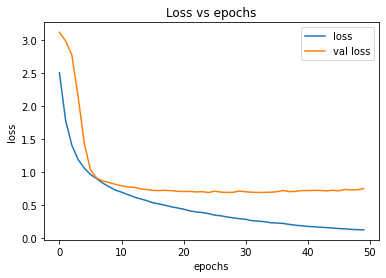

In [13]:
epochs = [i for i in range(50)]
plt.plot(epochs, train_stats.history['loss'], label='loss')
plt.plot(epochs, train_stats.history['val_loss'], label='val loss')

plt.title('Loss vs epochs')
plt.xlabel('epochs')
plt.ylabel('loss')
plt.legend()

plt.show()

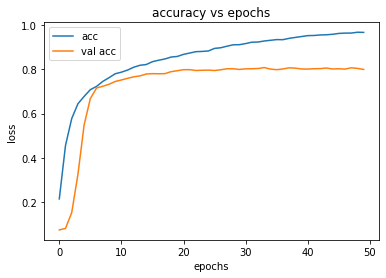

In [14]:
epochs = [i for i in range(50)]
plt.plot(epochs, train_stats.history['acc'], label= 'acc')
plt.plot(epochs, train_stats.history['val_acc'], label= 'val acc')

plt.title('accuracy vs epochs')
plt.xlabel('epochs')
plt.ylabel('loss')

plt.legend()
plt.show()

In [25]:
# Save model weights
model.save_weights('/kaggle/working/ResNet152_HAR-033-0.923063-0.804233.h5')


In [22]:
# Save model architecture
model_json = model.to_json()
with open('/kaggle/working/ResNet152.json', 'w') as json_file:
    json_file.write(model_json)

# Save weights
model.save_weights('/kaggle/working/ResNet152_HAR-033-0.923063-0.804233.h5')

print("Model architecture and weights saved!")


AttributeError: 'ResNet' object has no attribute 'to_json'

In [23]:
import os
print("Files in working directory:", os.listdir('/kaggle/working/'))


Files in working directory: ['.virtual_documents']


In [26]:
import os
print("Files in Current Directory:", os.listdir())


Files in Current Directory: ['.virtual_documents']


**TESTING**

In [17]:
#function to load test data
def create_test_generator(test_path):
    
    preprocess_fn = tf.keras.applications.resnet.preprocess_input
    SEED = 12
    IMG_HEIGHT = 224
    IMG_WIDTH = 224
    BATCH_SIZE = 64
    
    test_datagen = ImageDataGenerator(rescale= 1./255,
                                      preprocessing_function= preprocess_fn
                                     )
    
    test_generator = test_datagen.flow_from_directory(directory = test_path,
                                                       target_size = (IMG_HEIGHT ,IMG_WIDTH),
                                                        batch_size = BATCH_SIZE,
                                                        shuffle  = False , 
                                                        color_mode = "rgb",
                                                        class_mode = "categorical",
                                                        seed = 12
                                                      )
    
    return test_generator

In [19]:
def Load_Model(modelpath_json, weights_path):
    
    #loading the model
    json_file = open(modelpath_json, 'r')
    loaded_model_json = json_file.read()
    json_file.close()
    loaded_model = model_from_json(loaded_model_json)
    
    # load weights into new model
    loaded_model.load_weights(weights_path)
    print("Loaded model from disk")
    
    model = loaded_model
    clear_output()
    
    return model

def show_model_summary(model):
    
    model.summary()

In [20]:
def make_predictions(model, test_generator):
    
    preds = model.predict(test_generator)
    y_preds = np.argmax(preds , axis = 1)
    y_test = np.array(test_generator.labels)
    
    return y_preds, y_test

def classificn_report(y_test, y_preds):
    
    output_details = classification_report(y_test, y_preds, output_dict=True)
    print(classification_report(y_test, y_preds))
    return output_details

def generate_cm_data(y_test, y_preds):
    NUM_CLASSES = 15
    CLASS_LABELS  = ['calling', 'clapping', 'cycling', 'dancing', 'drinking', 'eating', 'fighting',
                    'hugging', 'laughing', 'listening_to_music', 'running', 'sitting', 'sleeping',
                    'texting', 'using_laptop']
    
    cm_data = confusion_matrix(y_test , y_preds)
    cm = pd.DataFrame(cm_data, columns=CLASS_LABELS, index = CLASS_LABELS)
    
    all_mod_rows = []
    for i in range(NUM_CLASSES):
        row = cm.iloc[i]
        row_total = 0
        for k in range(NUM_CLASSES):
            row_total += row[k]
        mod_row = []
        for j in range(NUM_CLASSES):
            mod_row.append(round(row[j]/row_total, 2))
        all_mod_rows.append(np.array(mod_row))
    
    return pd.DataFrame(all_mod_rows, columns=CLASS_LABELS, index=CLASS_LABELS)

In [21]:
def show_predictions(test_path, y_preds):
    
    CLASS_LABELS  = ['calling', 'clapping', 'cycling', 'dancing', 'drinking', 'eating', 'fighting',
                    'hugging', 'laughing', 'listening_to_music', 'running', 'sitting', 'sleeping',
                    'texting', 'using_laptop']
    IMG_HEIGHT = 224
    IMG_WIDTH = 224
    BATCH_SIZE = 64
    
    img_datagen = ImageDataGenerator(rescale = 1./255)
    img_generator = img_datagen.flow_from_directory(directory = test_path,
                                                       target_size = (IMG_HEIGHT ,IMG_WIDTH),
                                                        batch_size = BATCH_SIZE,
                                                        shuffle  = False , 
                                                        color_mode = "rgb",
                                                        class_mode = "categorical",
                                                        seed = 12
                                                      )
    clear_output()

    images, classes = next(img_generator)
    
    pred_lbls = [CLASS_LABELS[idx] for idx in y_preds]
    display_multiple_images(images, pred_lbls)
    
def display_one_image(image, title, subplot, color):
    plt.subplot(subplot)
    plt.axis('off')
    plt.imshow(image)
    plt.title(title, fontsize=16)
    
def display_multiple_images(images, titles, title_colors=None):
    subplot = 991
    plt.figure(figsize=(15,15))
    for i in range(9):
        color = 'black' if title_colors is None else title_colors[i]
        display_one_image(images[i], titles[i], subplot+i, color) 
    plt.tight_layout()
    plt.subplots_adjust(wspace=0.1, hspace=0.1)
    plt.show()

In [22]:
#generating test data
test_path = r"../input/human-action-recognition-dataset/Structured/test"
test_generator = create_test_generator(test_path)

Found 1890 images belonging to 15 classes.


In [28]:
import torch

# Assuming `model` is a PyTorch model (e.g., ResNet)
model_path = "/kaggle/working/ResNet152_HAR_model.pth"

# Save the entire model
torch.save(model.state_dict(), model_path)
print(f"Model saved to {model_path}")


Model saved to /kaggle/working/ResNet152_HAR_model.pth


In [29]:
import torch
import torchvision.models as models

# Define the model architecture (ResNet152 example)
model = models.resnet152(pretrained=False)  # Make sure this matches the original architecture

# Load the saved weights
model.load_state_dict(torch.load(model_path))
model.eval()  # Set the model to evaluation mode
print("Model reloaded successfully!")


RuntimeError: Error(s) in loading state_dict for ResNet:
	size mismatch for fc.weight: copying a param with shape torch.Size([6, 2048]) from checkpoint, the shape in current model is torch.Size([1000, 2048]).
	size mismatch for fc.bias: copying a param with shape torch.Size([6]) from checkpoint, the shape in current model is torch.Size([1000]).

In [32]:
import torch
import torchvision.models as models

# Define the same architecture
model = models.resnet152(pretrained=False)

# Modify the final layer to match the saved model's number of classes
num_classes = 6  # Replace with the correct number of classes
model.fc = torch.nn.Linear(model.fc.in_features, num_classes)

# Load the state_dict
model.load_state_dict(torch.load('/kaggle/working/ResNet152_HAR_model.pth'))
model.eval()  # Set the model to evaluation mode

print("Model reloaded successfully!")


Model reloaded successfully!


In [33]:
print(model.fc)


Linear(in_features=2048, out_features=6, bias=True)


In [34]:
torch.save(model, '/kaggle/working/ResNet152_HAR_model_full.pth')
print("Entire model saved successfully!")


Entire model saved successfully!


In [35]:
# Reload the full model directly
model = torch.load('/kaggle/working/ResNet152_HAR_model_full.pth')
model.eval()
print("Full model reloaded successfully!")


Full model reloaded successfully!


In [36]:
checkpoint = torch.load('/kaggle/working/ResNet152_HAR_model.pth')
print(checkpoint.keys())


odict_keys(['conv1.weight', 'bn1.weight', 'bn1.bias', 'bn1.running_mean', 'bn1.running_var', 'bn1.num_batches_tracked', 'layer1.0.conv1.weight', 'layer1.0.bn1.weight', 'layer1.0.bn1.bias', 'layer1.0.bn1.running_mean', 'layer1.0.bn1.running_var', 'layer1.0.bn1.num_batches_tracked', 'layer1.0.conv2.weight', 'layer1.0.bn2.weight', 'layer1.0.bn2.bias', 'layer1.0.bn2.running_mean', 'layer1.0.bn2.running_var', 'layer1.0.bn2.num_batches_tracked', 'layer1.0.conv3.weight', 'layer1.0.bn3.weight', 'layer1.0.bn3.bias', 'layer1.0.bn3.running_mean', 'layer1.0.bn3.running_var', 'layer1.0.bn3.num_batches_tracked', 'layer1.0.downsample.0.weight', 'layer1.0.downsample.1.weight', 'layer1.0.downsample.1.bias', 'layer1.0.downsample.1.running_mean', 'layer1.0.downsample.1.running_var', 'layer1.0.downsample.1.num_batches_tracked', 'layer1.1.conv1.weight', 'layer1.1.bn1.weight', 'layer1.1.bn1.bias', 'layer1.1.bn1.running_mean', 'layer1.1.bn1.running_var', 'layer1.1.bn1.num_batches_tracked', 'layer1.1.conv2.we

In [37]:
model.load_state_dict(torch.load('/kaggle/working/ResNet152_HAR_model.pth'), strict=False)


<All keys matched successfully>

In [20]:
  #loading saved model along with weights
model_path = '/kaggle/working/ResNet152.json'
weights_path = '/kaggle/working/ResNet152_HAR-033-0.923063-0.804233.h5'
model = Load_Model(model_path, weights_path)

model.summary()

NameError: name 'Load_Model' is not defined

In [25]:
# Save the full model as a single .h5 file
model.save('/kaggle/working/ResNet152_HAR_model.h5')
print("Model saved as ResNet152_HAR_model.h5 in /kaggle/working/")



AttributeError: 'ResNet' object has no attribute 'save'

In [29]:
#predictions
y_preds, y_test = make_predictions(model, test_generator)
print('Done')

Done


In [30]:
#evaluating classification report
output_details = classificn_report(y_test, y_preds)

print('Accuracy', output_details['accuracy'])
# 0 --> calling
# 1 --> clapping
# 2 --> cycling
# 3 --> dancing
# 4 --> drinking
# 5 --> eating
# 6 --> fighting
# 7 --> hugging
# 8 --> laughing
# 9 --> listening_to_music
# 10 --> running
# 11 --> sitting
# 12 --> sleeping
# 13 --> texting
# 14 --> using_laptop

              precision    recall  f1-score   support

           0       0.82      0.69      0.75       126
           1       0.87      0.63      0.73       126
           2       0.92      0.97      0.95       126
           3       0.78      0.82      0.80       126
           4       0.83      0.85      0.84       126
           5       0.92      0.92      0.92       126
           6       0.84      0.77      0.80       126
           7       0.80      0.79      0.80       126
           8       0.80      0.87      0.83       126
           9       0.60      0.82      0.69       126
          10       0.88      0.85      0.87       126
          11       0.62      0.67      0.64       126
          12       0.86      0.83      0.85       126
          13       0.83      0.71      0.77       126
          14       0.74      0.81      0.77       126

    accuracy                           0.80      1890
   macro avg       0.81      0.80      0.80      1890
weighted avg       0.81   

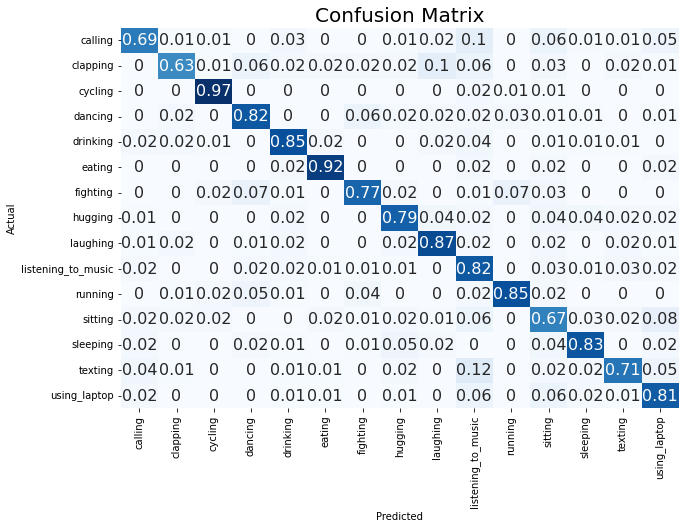

In [31]:
#plotting confusion matrix (in terms of recall scores)
cm = generate_cm_data(y_test, y_preds)
cm.index.name = 'Actual'
cm.columns.name = 'Predicted'
plt.figure(figsize = (10,7))
plt.title('Confusion Matrix', fontsize = 20)
sns.set(font_scale=1.2)
ax = sns.heatmap(cm, cbar=False, cmap="Blues", annot=True, annot_kws={"size": 16}, fmt='g')

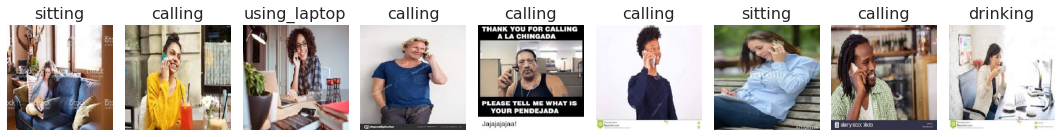

In [32]:
show_predictions(test_path, y_preds)

In [38]:
import torch
import torchvision.models as models
import torchvision.transforms as transforms
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

# Load ResNet152 model
model = models.resnet152(pretrained=True)
model.eval()  # Set the model to evaluation mode

# Modify the final layer if trained for HAR with fewer classes
num_classes = 6  # Replace with your number of classes
model.fc = torch.nn.Linear(model.fc.in_features, num_classes)
model.load_state_dict(torch.load('/kaggle/working/ResNet152_HAR_model.pth'))

print("Model loaded successfully!")


Downloading: "https://download.pytorch.org/models/resnet152-394f9c45.pth" to /root/.cache/torch/hub/checkpoints/resnet152-394f9c45.pth


  0%|          | 0.00/230M [00:00<?, ?B/s]

Model loaded successfully!


In [39]:
!pip install --upgrade ipywidgets


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 139.8/139.8 kB 6.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 214.4/214.4 kB 15.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 64.4 MB/s eta 0:00:00:00:01
  Attempting uninstall: widgetsnbextension
    Found existing installation: widgetsnbextension 3.6.1
    Uninstalling widgetsnbextension-3.6.1:
      Successfully uninstalled widgetsnbextension-3.6.1
  Attempting uninstall: jupyterlab-widgets
    Found existing installation: jupyterlab-widgets 1.1.1
    Uninstalling jupyterlab-widgets-1.1.1:
      Successfully uninstalled jupyterlab-widgets-1.1.1
  Attempting uninstall: ipywidgets
    Found existing installation: ipywidgets 7.7.1
    Uninstalling ipywidgets-7.7.1:
      Successfully uninstalled ipywidgets-7.7.1
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipyleaflet

In [94]:
import ipywidgets as widgets
print(f"ipywidgets version: {widgets.__version__}")


ipywidgets version: 7.7.1


In [96]:
import os
os.environ['JUPYTER_WIDGETS_CONTROL'] = 'disable'


In [97]:
from tqdm.notebook import tqdm
for i in tqdm(range(100)):
    pass


  0%|          | 0/100 [00:00<?, ?it/s]

In [98]:
import torch
import torchvision.models as models

# Load ResNet152
model = models.resnet152(pretrained=True)
model.eval()
print("Model loaded successfully!")


Model loaded successfully!


In [99]:
import torch
import torchvision.models as models
import torchvision.transforms as transforms
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

# Load ResNet152 model
model = models.resnet152(pretrained=True)
model.eval()  # Set the model to evaluation mode

# Modify the final layer if trained for HAR with fewer classes
num_classes = 6  # Replace with your number of classes
model.fc = torch.nn.Linear(model.fc.in_features, num_classes)
model.load_state_dict(torch.load('/kaggle/working/ResNet152_HAR_model.pth'))

print("Model loaded successfully!")


Model loaded successfully!


In [100]:
# Image preprocessing function
def preprocess_image(image_path, input_size=224):
    transform = transforms.Compose([
        transforms.Resize((input_size, input_size)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ])
    image = Image.open(image_path).convert('RGB')
    image_tensor = transform(image).unsqueeze(0)  # Add batch dimension
    return image_tensor, image

# Load and preprocess an example image
image_path = '/kaggle/input/human-action-recognition-dataset/Structured/test/calling/Image_10899.jpg'
input_tensor, original_image = preprocess_image(image_path)


In [102]:
#For GradCAM operation where model based XAI work
class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None 

        # Hook to save activations and gradients
        target_layer.register_forward_hook(self._save_activations)
        target_layer.register_backward_hook(self._save_gradients)

    def _save_activations(self, module, input, output):
        self.activations = output

    def _save_gradients(self, module, grad_in, grad_out):
        self.gradients = grad_out[0]

    def generate(self, input_tensor, target_class):
        # Forward pass
        output = self.model(input_tensor)

        # Backward pass
        self.model.zero_grad()
        target = output[0][target_class]
        target.backward()

        # Compute Grad-CAM
        gradients = self.gradients.cpu().detach().numpy()
        activations = self.activations.cpu().detach().numpy()
        weights = np.mean(gradients, axis=(2, 3))  # Average gradients
        cam = np.sum(weights[:, :, None, None] * activations, axis=1).squeeze(0)
        cam = np.maximum(cam, 0)  # Apply ReLU
        cam = cam / cam.max()  # Normalize
        return cam


In [103]:
#here find the targated layer ...
# Set the target layer (last convolutional layer in ResNet152)
target_layer = model.layer4[-1]
grad_cam = GradCAM(model, target_layer)

# Generate Grad-CAM for the desired class (e.g., class index 0)
target_class = 0  # Update with the class you want to analyze
cam = grad_cam.generate(input_tensor, target_class)
print("Grad-CAM heatmap generated!")


Grad-CAM heatmap generated!


/opt/conda/lib/python3.7/site-packages/ipykernel_launcher.py:34: RuntimeWarning: invalid value encountered in true_divide


/opt/conda/lib/python3.7/site-packages/ipykernel_launcher.py:4: DeprecationWarning: ANTIALIAS is deprecated and will be removed in Pillow 10 (2023-07-01). Use Resampling.LANCZOS instead.
  after removing the cwd from sys.path.


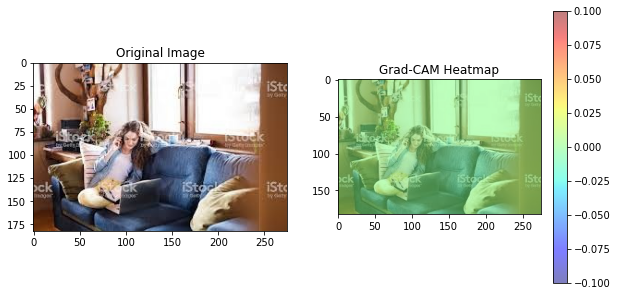

In [104]:
#Output based on th GradCAM (XAI)
# Resize CAM to match the original image size
cam_resized = np.uint8(255 * cam)  # Scale to 0-255
cam_resized = Image.fromarray(cam_resized).resize(original_image.size, Image.ANTIALIAS)

# Plot the original image and Grad-CAM heatmap
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(original_image)
plt.title("Original Image")

plt.subplot(1, 2, 2)
plt.imshow(original_image)
plt.imshow(cam_resized, cmap='jet', alpha=0.5)  # Overlay heatmap
plt.title("Grad-CAM Heatmap")
plt.colorbar()
plt.show()


In [105]:
# Grad-CAM function
def generate_gradcam(model, input_tensor, target_class=None, layer_name='layer4'):
    # Hook to capture gradients and activations
    gradients = []
    activations = []

    def backward_hook(module, grad_input, grad_output):
        gradients.append(grad_output[0])

    def forward_hook(module, input, output):
        activations.append(output)

    # Register hooks
    layer = dict(model.named_modules())[layer_name]
    layer.register_forward_hook(forward_hook)
    layer.register_backward_hook(backward_hook)

    # Forward pass
    outputs = model(input_tensor)
    if target_class is None:
        target_class = torch.argmax(outputs, dim=1).item()
    score = outputs[:, target_class]

    # Backward pass
    model.zero_grad()
    score.backward()

    # Compute Grad-CAM
    grads = gradients[0].detach().cpu().numpy()
    activ = activations[0].detach().cpu().numpy()

    pooled_grads = np.mean(grads, axis=(2, 3), keepdims=True)
    heatmap = np.mean(pooled_grads * activ, axis=1).squeeze()
    heatmap = np.maximum(heatmap, 0)  # ReLU to keep positive influences
    heatmap /= np.max(heatmap)  # Normalize
    return heatmap


/opt/conda/lib/python3.7/site-packages/ipykernel_launcher.py:4: DeprecationWarning: LANCZOS is deprecated and will be removed in Pillow 10 (2023-07-01). Use Resampling.LANCZOS instead.
  after removing the cwd from sys.path.


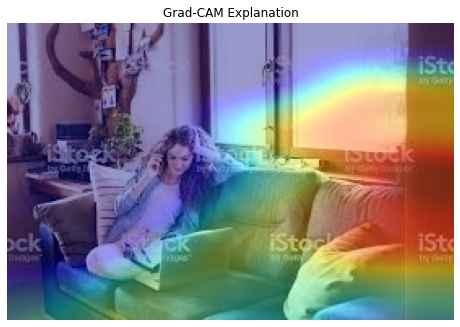

In [106]:
# Overlay Grad-CAM heatmap on the original image
def overlay_gradcam(heatmap, original_image, alpha=0.4):
    heatmap = np.uint8(255 * heatmap)  # Scale heatmap to 0-255
    heatmap = Image.fromarray(heatmap).resize(original_image.size, Image.LANCZOS)
    heatmap = np.asarray(heatmap)
    heatmap = plt.cm.jet(heatmap / 255.0)[:, :, :3]  # Apply colormap

    # Overlay heatmap on original image
    original_image_np = np.asarray(original_image) / 255.0
    overlayed_image = (1 - alpha) * original_image_np + alpha * heatmap
    return np.clip(overlayed_image, 0, 1)

# Generate Grad-CAM heatmap
heatmap = generate_gradcam(model, input_tensor, layer_name='layer4')

# Overlay heatmap on the original image
overlayed_image = overlay_gradcam(heatmap, original_image)

# Display the image
plt.figure(figsize=(8, 8))
plt.imshow(overlayed_image)
plt.axis('off')
plt.title("Grad-CAM Explanation")
plt.show()


In [107]:
#Reduce Latency part
import time

start_time = time.time()
heatmap = generate_gradcam(model, input_tensor, layer_name='layer4')
overlayed_image = overlay_gradcam(heatmap, original_image)
end_time = time.time()

print(f"Latency: {end_time - start_time:.2f} seconds")


Latency: 0.57 seconds


/opt/conda/lib/python3.7/site-packages/ipykernel_launcher.py:4: DeprecationWarning: LANCZOS is deprecated and will be removed in Pillow 10 (2023-07-01). Use Resampling.LANCZOS instead.
  after removing the cwd from sys.path.


In [108]:
output_path = '/kaggle/working/gradcam_result.png'
overlayed_image_uint8 = (overlayed_image * 255).astype(np.uint8)  # Convert to uint8
Image.fromarray(overlayed_image_uint8).save(output_path)

print(f"Grad-CAM result saved to {output_path}")


Grad-CAM result saved to /kaggle/working/gradcam_result.png


In [109]:
def batch_gradcam(model, input_tensor_batch, layer_name='layer4'):
    # Process a batch of images for Grad-CAM
    outputs = model(input_tensor_batch)
    predictions = torch.argmax(outputs, dim=1)
    heatmaps = []
    for i in range(len(input_tensor_batch)):
        heatmaps.append(generate_gradcam(model, input_tensor_batch[i].unsqueeze(0), predictions[i], layer_name))
    return heatmaps


In [110]:
import os
from torchvision import transforms, datasets
from torch.utils.data import DataLoader

# Path to your dataset (adjust as needed)
data_dir = "/kaggle/input/human-action-recognition-dataset"

# Preprocessing pipeline for ResNet152
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

# Load dataset
dataset = datasets.ImageFolder(data_dir, transform=transform)
data_loader = DataLoader(dataset, batch_size=16, shuffle=False, num_workers=4)

print(f"Dataset loaded with {len(dataset)} images.")


Dataset loaded with 12600 images.
